In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('../data/processed/metadata.csv')

In [3]:
df.head()

,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,treatment_protocol_ch1,...,contact_zip/postal_code,contact_country,supplementary_file,data_row_count,tissue_ch1,sample_type_ch1,tissue_ch2,age_ch2,gender_ch2,disease_status_ch2
0,PFC_1,GSM1423780,Public on Jul 31 2014,Jul 01 2014,Jul 31 2014,RNA,2,HBTRC_PF_Pool_1,Homo sapiens,NaN,...,10029,USA,NONE,39280,prefrontal cortex brain,reference,prefrontal cortex brain,67 yrs,female,Alzheimer's disease
1,PFC_2,GSM1423781,Public on Jul 31 2014,Jul 01 2014,Jul 31 2014,RNA,2,HBTRC_PF_Pool_2,Homo sapiens,NaN,...,10029,USA,NONE,39280,prefrontal cortex brain,reference,prefrontal cortex brain,88 yrs,male,Alzheimer's disease
2,PFC_3,GSM1423782,Public on Jul 31 2014,Jul 01 2014,Jul 31 2014,RNA,2,HBTRC_PF_Pool_3,Homo sapiens,NaN,...,10029,USA,NONE,39280,prefrontal cortex brain,reference,prefrontal cortex brain,62 yrs,male,Alzheimer's disease
3,PFC_4,GSM1423783,Public on Jul 31 2014,Jul 01 2014,Jul 31 2014,RNA,2,HBTRC_PF_Pool_4,Homo sapiens,NaN,...,10029,USA,NONE,39280,prefrontal cortex brain,reference,prefrontal cortex brain,90 yrs,female,Alzheimer's disease
4,PFC_5,GSM1423784,Public on Jul 31 2014,Jul 01 2014,Jul 31 2014,RNA,2,HBTRC_PF_Pool_5,Homo sapiens,NaN,...,10029,USA,NONE,39280,prefrontal cortex brain,reference,prefrontal cortex brain,90 yrs,female,Alzheimer's disease


### Filtering data

In [4]:
# Keep only columns with different values and not all NaN
df = df.loc[:, df.nunique() > 1]

In [5]:
# Convert age into integer
df['age_ch2'] = df['age_ch2'].apply(lambda x: x.split(' ')[0]).astype(int)

In [6]:
# Removing Huntington's disease patients
df = df[df['disease_status_ch2'] != 'Huntington\'s disease']

In [7]:
# Save geo_accession
geo_accession = df['geo_accession']

# Remove columns with identifiers
df = df.loc[:, df.nunique() != df.shape[0]]

# Add geo_accession
df['geo_accession'] = geo_accession

In [8]:
df.head()

,age_ch2,gender_ch2,disease_status_ch2,geo_accession
0,67,female,Alzheimer's disease,GSM1423780
1,88,male,Alzheimer's disease,GSM1423781
2,62,male,Alzheimer's disease,GSM1423782
3,90,female,Alzheimer's disease,GSM1423783
4,90,female,Alzheimer's disease,GSM1423784


In [9]:
def create_comparison_table(data):
    data = data.copy()

    # Create a new columns to calculate the number of females
    data['is_female'] = data['gender_ch2'] == 'female'

    # Grouped by disease
    disease_group = data.groupby(['disease_status_ch2'])

    group = list(disease_group.indices.keys())

    n = disease_group['age_ch2'].count().values

    mean = disease_group['age_ch2'].mean().values
    std = disease_group['age_ch2'].std().values
    min_age = disease_group['age_ch2'].min().values
    max_age = disease_group['age_ch2'].max().values

    # Age - AD
    age_ad = f'{round(mean[0], 1)} ± {round(std[0], 1)} years'

    # Age - non-demented
    age_not_ad = f'{round(mean[1], 1)} ± {round(std[1], 1)} years'

    # Percentage
    percentage = disease_group['is_female'].mean().values
    pct_alzheimers_female = f'{round(percentage[0] * 100, 1)}%'
    pct_not_alzheimers_female = f'{round(percentage[1] * 100, 1)}%'

    table = {
        'group': [group[0], group[1]],
        'n': [n[0], n[1]],
        'age (min)': [min_age[0], min_age[1]],
        'age (max)': [max_age[0], max_age[1]],
        'age (mean ± std)': [age_ad, age_not_ad],
        'female': [pct_alzheimers_female, pct_not_alzheimers_female],
    }

    return pd.DataFrame(table)

In [10]:
table_1 = create_comparison_table(df)
table_1

,group,n,age (min),age (max),age (mean ± std),female
0,Alzheimer's disease,310,53,100,80.6 ± 9.0 years,56.5%
1,non-demented,157,22,106,63.5 ± 9.9 years,21.7%


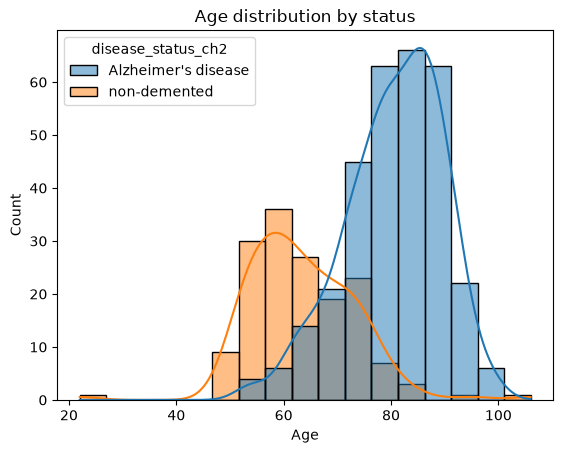

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

ax = sns.histplot(df, x='age_ch2', hue='disease_status_ch2', kde=True)
ax.set(title='Age distribution by status', xlabel='Age', ylabel='Count')
ax.figure.savefig('../figures/age_distribution_by_status.png')

plt.show()

In [12]:
SIGNIFICANCE_VALUE = 0.05

from scipy.stats import mannwhitneyu

ad = df[df['disease_status_ch2'] == 'Alzheimer\'s disease']
not_ad = df[df['disease_status_ch2'] == 'non-demented']

U1, p = mannwhitneyu(ad['age_ch2'], not_ad['age_ch2'])
if p < SIGNIFICANCE_VALUE:
    print(f'p-value: {p}. We can see there\'s a difference in the groups.')
else:
    print(f'p-value: {p}. We cannot conclude anything.')

p-value: 2.692890943264235e-45. We can see there's a difference in the groups.


In [13]:
from scipy.stats import chi2_contingency

# Crosstab table to group and count by gender and disease status
crosstab_table = pd.crosstab(df['gender_ch2'], df['disease_status_ch2'])
result = chi2_contingency(crosstab_table)

p_chi2 = result.pvalue

if p_chi2 < SIGNIFICANCE_VALUE:
    print(f'p-value: {p_chi2}. Gender is associated to disease status.')
else:
    print(f'p-value: {p_chi2}. We cannot conclude anything.')

p-value: 1.850460008111882e-12. Gender is associated to disease status.


In [14]:
table_2 = create_comparison_table(df[(df['age_ch2'] >= 53) & (df['age_ch2'] <= 100)])
table_2

,group,n,age (min),age (max),age (mean ± std),female
0,Alzheimer's disease,310,53,100,80.6 ± 9.0 years,56.5%
1,non-demented,143,53,95,64.6 ± 8.3 years,23.1%


In [15]:
# Save new data without Huntington's disease
df.to_csv('../data/processed/metadata_ad_control.csv', index=False)